<a href="https://colab.research.google.com/github/lovkush7/MACHINE-LEARNING-/blob/main/Titinic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
path = "/content/drive/MyDrive/machinelearning/titanic_logistic_regression.csv"

In [3]:
import pandas as pd
data = pd.read_csv(path)

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [4]:
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22,1,0,7.25,S
1,1,1,female,38,1,0,71.28,C
2,1,3,female,26,0,0,7.92,S
3,1,1,female,35,1,0,53.10,S
4,0,3,male,35,0,0,8.05,S


In [5]:
data.shape

(50, 8)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  50 non-null     int64  
 1   Pclass    50 non-null     int64  
 2   Sex       50 non-null     object 
 3   Age       50 non-null     int64  
 4   SibSp     50 non-null     int64  
 5   Parch     50 non-null     int64  
 6   Fare      50 non-null     float64
 7   Embarked  50 non-null     object 
dtypes: float64(1), int64(5), object(2)
memory usage: 3.3+ KB


In [7]:
data.duplicated().sum()

np.int64(0)

In [9]:
data['Survived'].value_counts()

,count
Survived,
1,28
0,22


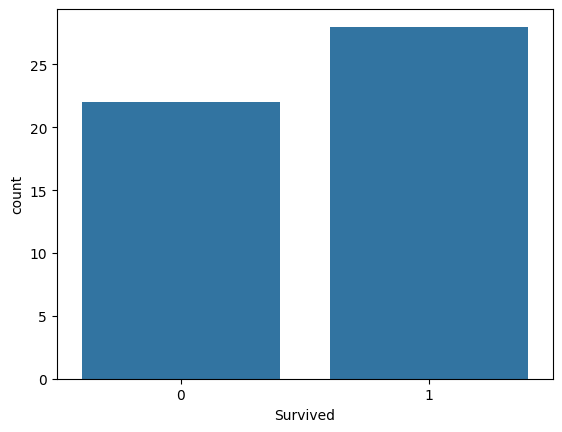

In [11]:
sns.countplot(x='Survived', data=data)
plt.show()

In [12]:
num_col = data.select_dtypes(include="number").columns
cat_col = data.select_dtypes(include="object").columns

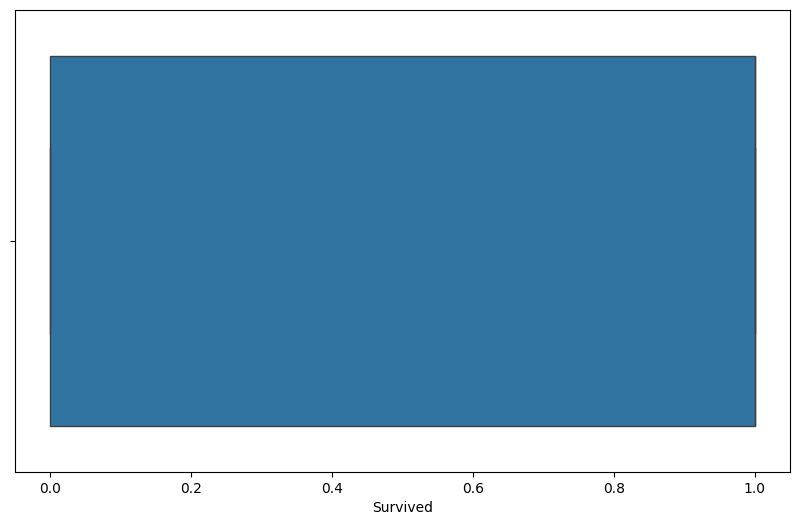

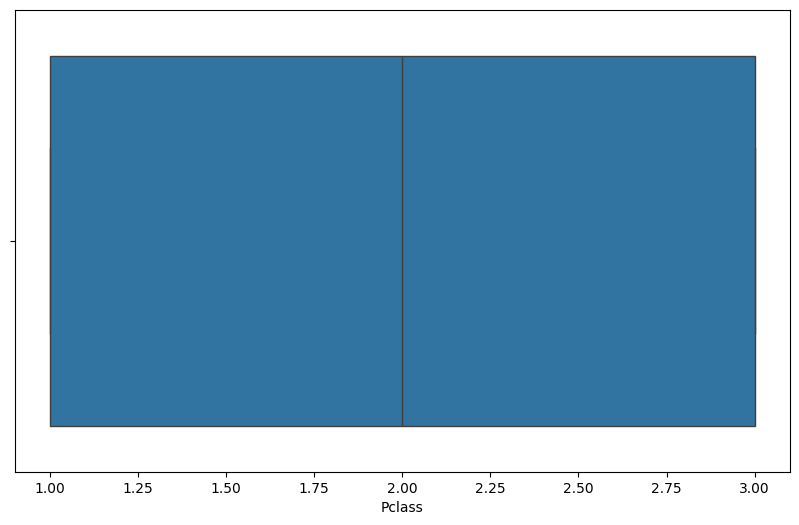

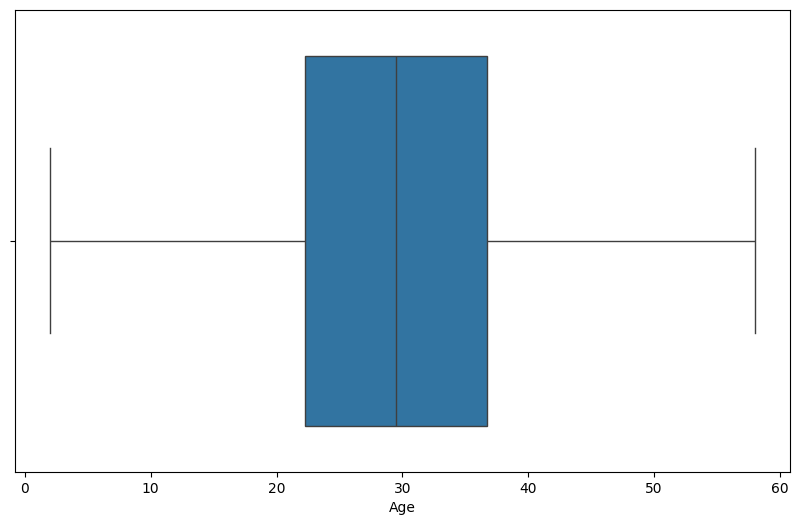

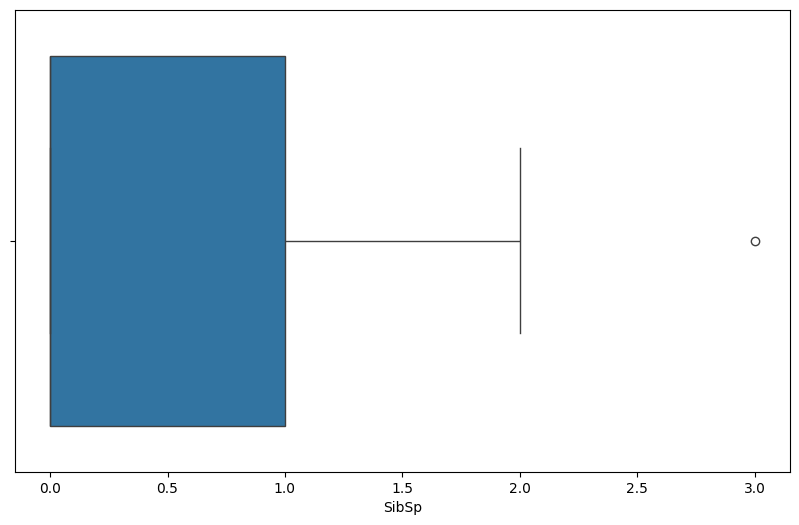

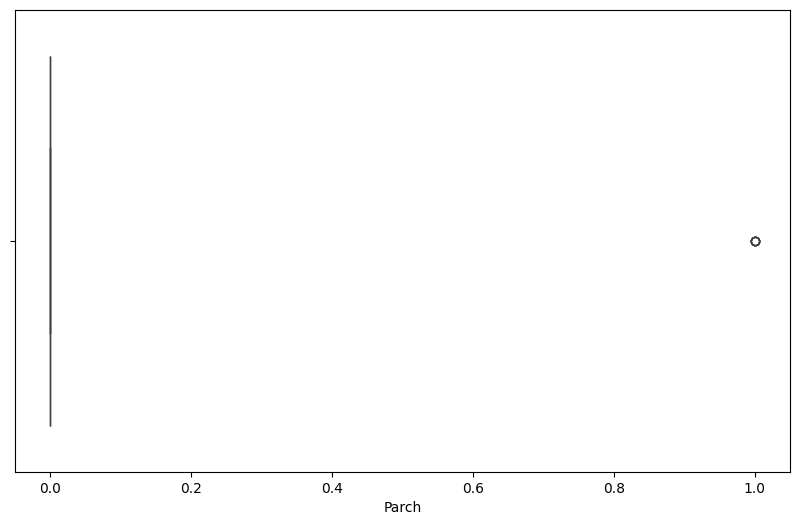

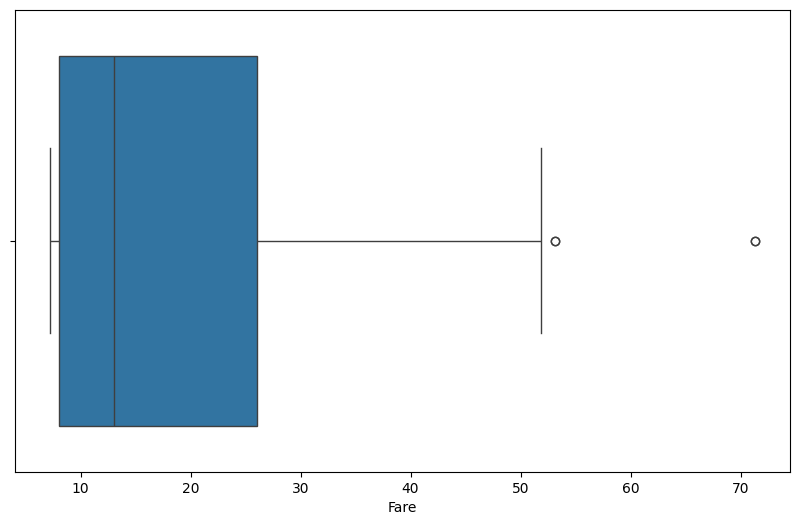

In [19]:
for col in num_col:
  plt.figure(figsize=(10,6))
  sns.boxplot(x=data[col])

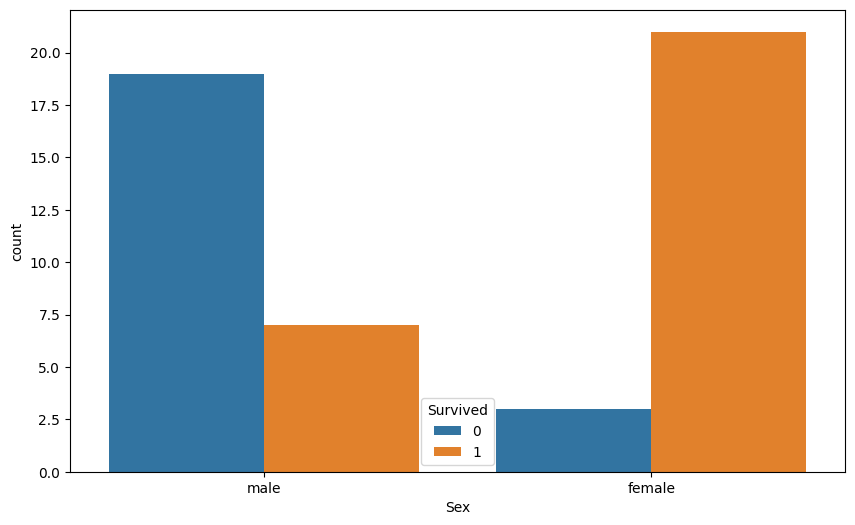

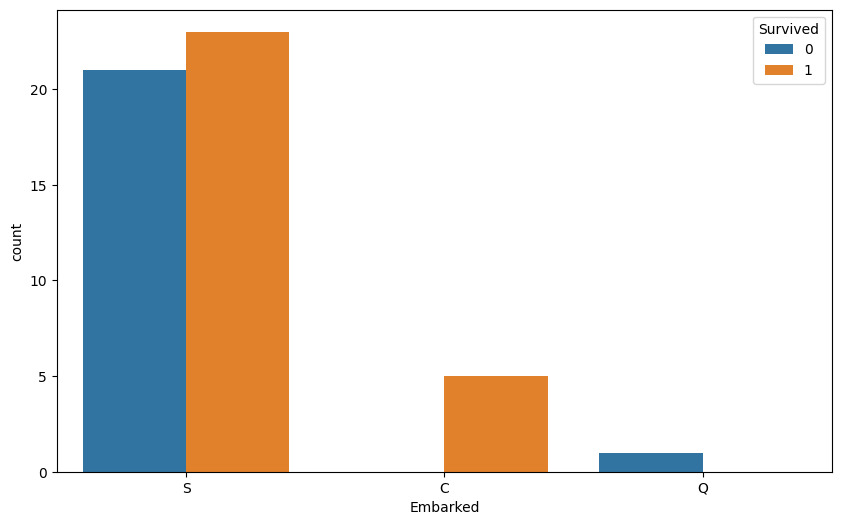

In [22]:
for col in cat_col:
  plt.figure(figsize=(10,6))
  sns.countplot(x=data[col], hue=data['Survived'], data=data)


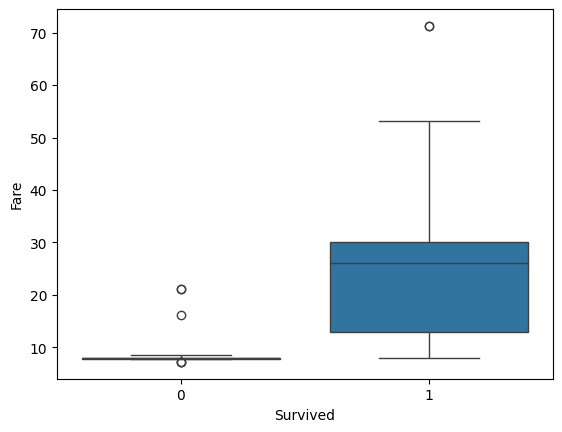

In [26]:
sns.boxplot(x="Survived", y="Fare", data=data)
plt.show()

In [28]:
x=data.drop("Survived",axis=1)
y= data['Survived']

In [30]:
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22,1,0,7.25,S
1,1,1,female,38,1,0,71.28,C
2,1,3,female,26,0,0,7.92,S
3,1,1,female,35,1,0,53.10,S
4,0,3,male,35,0,0,8.05,S


In [31]:
x = pd.get_dummies(x, columns=["Sex","Embarked" ], drop_first=True)

In [32]:
x.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,22,1,0,7.25,True,False,True
1,1,38,1,0,71.28,False,False,False
2,3,26,0,0,7.92,False,False,True
3,1,35,1,0,53.10,False,False,True
4,3,35,0,0,8.05,True,False,True


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [37]:
X_train.shape

(40, 8)

In [38]:
X_test.shape

(10, 8)

In [39]:
scaler = StandardScaler()

In [42]:
numeric_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

In [43]:
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [45]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [46]:
y_pred = model.predict(X_test)

In [47]:
y_pred

array([0, 1, 0, 0, 1, 1, 1, 0, 0, 1])

In [48]:
print("Actual:", y_test.values)
print("Predicted:", y_pred)

Actual: [0 1 0 0 1 1 1 1 0 1]
Predicted: [0 1 0 0 1 1 1 0 0 1]


In [49]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[4 0]
 [1 5]]


In [50]:
accuracy = accuracy_score(y_test, y_pred)

print(accuracy)

0.9


In [51]:
precision = precision_score(y_test, y_pred)

print(precision)

1.0


In [52]:
recall = recall_score(y_test, y_pred)

print(recall)

0.8333333333333334


In [53]:
f1 = f1_score(y_test, y_pred)

print(f1)

0.9090909090909091


In [54]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

Accuracy : 0.9
Precision: 1.0
Recall   : 0.8333333333333334
F1 Score : 0.9090909090909091


In [55]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      1.00      0.89         4
           1       1.00      0.83      0.91         6

    accuracy                           0.90        10
   macro avg       0.90      0.92      0.90        10
weighted avg       0.92      0.90      0.90        10

